In [735]:
# !pip install pandas --quiet
# !pip install sklearn --quiet

In [736]:
# !pip install seaborn --quiet

In [737]:
import pandas as pd

manual_df = pd.read_csv('./datasets/ruler_digit/px_per_cm.csv')
auto_df = pd.read_csv('./results.csv')

In [738]:
manual_df

,img_id,manual_measure,is_from_train_set
0,DSC_0619,161,True
1,DSC_0232,128,True
2,DSC_0600,217,True
3,DSC_0348,159,True
4,DSC_0457,209,True
...,...,...,...
179,IMG_1629,404,False
180,IMG_1612,311,False
181,IMG_1627,160,False
182,IMG_1624,297,False


In [739]:
auto_df

,img_id,px_per_unit
0,DSC_0619,157
1,DSC_0232,None
2,DSC_0600,185
3,DSC_0348,160
4,DSC_0457,205
...,...,...
179,IMG_1629,None
180,IMG_1612,320
181,IMG_1627,None
182,IMG_1624,289


In [740]:
merged_df = manual_df.merge(auto_df, on='img_id')

In [741]:
merged_df

,img_id,manual_measure,is_from_train_set,px_per_unit
0,DSC_0619,161,True,157
1,DSC_0232,128,True,None
2,DSC_0600,217,True,185
3,DSC_0348,159,True,160
4,DSC_0457,209,True,205
...,...,...,...,...
179,IMG_1629,404,False,None
180,IMG_1612,311,False,320
181,IMG_1627,160,False,None
182,IMG_1624,297,False,289


In [742]:
only_predicted_df = merged_df[merged_df['px_per_unit'] != 'None']

In [743]:
only_predicted_df

,img_id,manual_measure,is_from_train_set,px_per_unit
0,DSC_0619,161,True,157
2,DSC_0600,217,True,185
3,DSC_0348,159,True,160
4,DSC_0457,209,True,205
5,DSC_0477,174,True,172
...,...,...,...,...
176,IMG_1904,242,False,252
177,IMG_1611,307,False,308
180,IMG_1612,311,False,320
182,IMG_1624,297,False,289


In [744]:
only_predicted_df['px_per_unit'] = only_predicted_df['px_per_unit'].astype('float').round(decimals=0)

/tmp/ipykernel_12877/3916084023.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  only_predicted_df['px_per_unit'] = only_predicted_df['px_per_unit'].astype('float').round(decimals=0)


In [745]:
only_predicted_df

,img_id,manual_measure,is_from_train_set,px_per_unit
0,DSC_0619,161,True,157.0
2,DSC_0600,217,True,185.0
3,DSC_0348,159,True,160.0
4,DSC_0457,209,True,205.0
5,DSC_0477,174,True,172.0
...,...,...,...,...
176,IMG_1904,242,False,252.0
177,IMG_1611,307,False,308.0
180,IMG_1612,311,False,320.0
182,IMG_1624,297,False,289.0


In [746]:
from sklearn.metrics import mean_absolute_error

In [747]:
mae_values = []
mae_percentage_values = []
for idx, row in only_predicted_df.iterrows():
    y = int(row[' manual_measure'])
    y_hat = int(row['px_per_unit'])
    mae = mean_absolute_error([y], [y_hat])
    mae_values.append(mae)
    mae_percentage_values.append(mae * 100 / y_hat)

In [748]:
import numpy as np
np.argmax(mae_values)

62

In [749]:
max(mae_values)

58.0

In [750]:
mae_values

[4.0,
 32.0,
 1.0,
 4.0,
 2.0,
 28.0,
 1.0,
 2.0,
 2.0,
 2.0,
 2.0,
 11.0,
 10.0,
 1.0,
 4.0,
 3.0,
 14.0,
 5.0,
 3.0,
 0.0,
 5.0,
 7.0,
 6.0,
 6.0,
 7.0,
 15.0,
 13.0,
 2.0,
 1.0,
 6.0,
 3.0,
 9.0,
 2.0,
 7.0,
 1.0,
 3.0,
 2.0,
 1.0,
 7.0,
 4.0,
 9.0,
 23.0,
 3.0,
 24.0,
 14.0,
 7.0,
 12.0,
 7.0,
 3.0,
 8.0,
 3.0,
 5.0,
 2.0,
 2.0,
 1.0,
 2.0,
 4.0,
 4.0,
 1.0,
 1.0,
 2.0,
 0.0,
 58.0,
 7.0,
 3.0,
 6.0,
 8.0,
 8.0,
 7.0,
 19.0,
 2.0,
 5.0,
 5.0,
 2.0,
 6.0,
 16.0,
 2.0,
 2.0,
 2.0,
 2.0,
 1.0,
 5.0,
 3.0,
 6.0,
 3.0,
 1.0,
 6.0,
 15.0,
 7.0,
 2.0,
 0.0,
 7.0,
 9.0,
 1.0,
 7.0,
 4.0,
 0.0,
 3.0,
 7.0,
 5.0,
 17.0,
 32.0,
 8.0,
 2.0,
 3.0,
 1.0,
 1.0,
 1.0,
 17.0,
 7.0,
 10.0,
 28.0,
 10.0,
 3.0,
 10.0,
 2.0,
 1.0,
 5.0,
 18.0,
 7.0,
 4.0,
 1.0,
 4.0,
 10.0,
 1.0,
 9.0,
 8.0,
 2.0]

In [751]:
import matplotlib.pyplot as plt

In [752]:
import seaborn as sns

In [753]:
import numpy as np

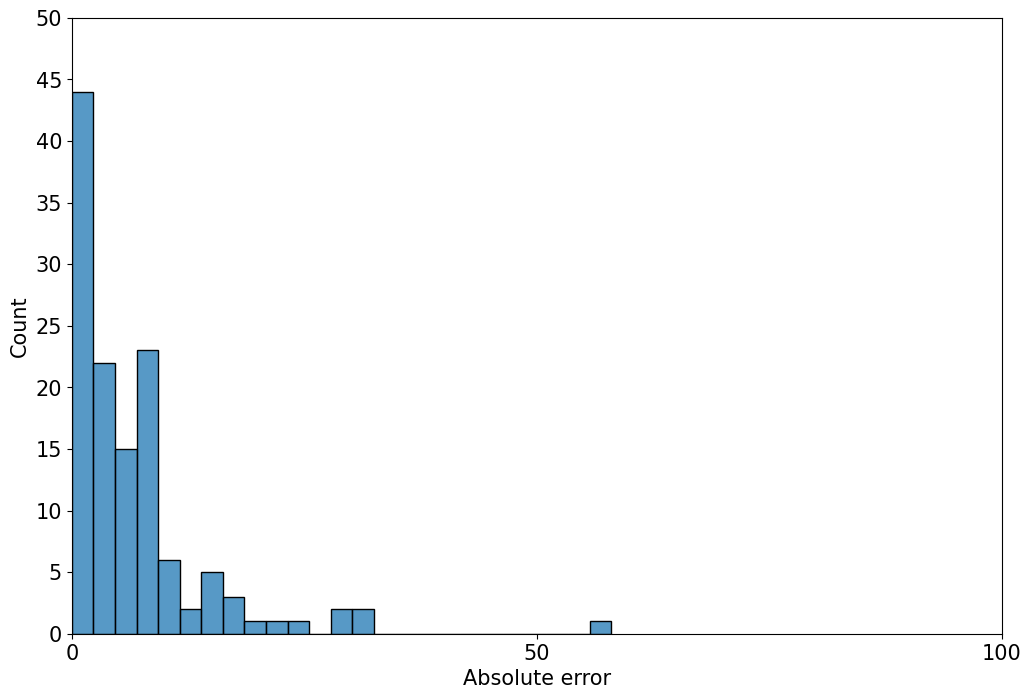

In [754]:
plt.figure(figsize=(12, 8))
plot = sns.histplot(mae_values)
min_x = int(min(mae_values))
max_x = int(max(mae_values))
y_ticks = plot.get_yticks()
min_y = int(min(y_ticks))
max_y = int(max(y_ticks))
plot.set_xlabel('Absolute error')
plot.margins(x=0)
# plot.yaxis.grid()
plot.set_yticks(range(min_y, max_y+5, 5))
plot.set_xticks(range(min_x, max_x+50, 50))
# plt.rcParams.update({'font.size': 22});
plt.rc('font', size=15);

In [755]:
np.median(mae_values)

4.0

In [756]:
np.mean(mae_values)

6.6328125

In [757]:
np.median(mae_percentage_values)

2.141847223814437

In [758]:
np.mean(mae_percentage_values)

3.5341683902559753